In [1]:
# House Price Prediction

## Project objective
'''
The goal is to predict the SalePrice of each house in the test dataset. This is a regression problem because the value we want to predict is a number.
This notebook contains the work completed so far: data loading, exploratory data analysis, exploratory feature engineering, and missing-value investigation.
'''

'\nThe goal is to predict the SalePrice of each house in the test dataset. This is a regression problem because the value we want to predict is a number.\nThis notebook contains the work completed so far: data loading, exploratory data analysis, exploratory feature engineering, and missing-value investigation.\n'

In [2]:
'''
Project roadmap
1. Understand the problem and the data.
2. Explore the target and selected features. 
3. Split the labeled data into training and validation sets. (future step)
4. Build preprocessing fitted only on the training data. (future step)
5. Train and evaluate a baseline model. (future step)
6. Improve the model and create a Kaggle submission. (future step)
'''

'\nProject roadmap\n1. Understand the problem and the data.\n2. Explore the target and selected features. \n3. Split the labeled data into training and validation sets. (future step)\n4. Build preprocessing fitted only on the training data. (future step)\n5. Train and evaluate a baseline model. (future step)\n6. Improve the model and create a Kaggle submission. (future step)\n'

In [3]:
# Import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [4]:
                                                                                        # PROBLEM UNDERSTANDING
''' 
 Target: SalePrice
 Problem type: Regression
 Input: LotArea + GrLivArea, OverallQual,  
'''

' \n Target: SalePrice\n Problem type: Regression\n Input: LotArea + GrLivArea, OverallQual,  \n'

In [5]:
                                                                                        # DATA UNDERSTANDING                                                                                    

In [6]:
# Load training data 
train_data = pd.read_csv("train.csv")
train_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
# Load testing data 
test_data = pd.read_csv("test.csv")
test_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [8]:
# Understand the target variable
prices = train_data["SalePrice"]
# Descriptive statistics for SalePrice
prices.describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

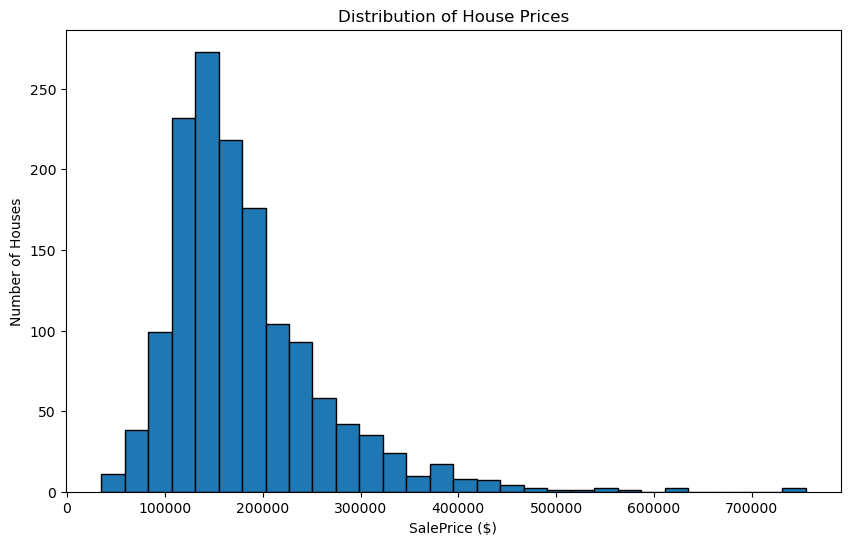

In [9]:
# Histogram distribution of SalePrice
plt.figure(figsize=(10,6))
plt.hist(train_data["SalePrice"], bins=30, edgecolor="black")

plt.xlabel("SalePrice ($)")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Prices")

plt.show()

In [10]:
# Mean and median SalePrice

In [11]:
train_data["SalePrice"].mean()

np.float64(180921.19589041095)

In [12]:
train_data["SalePrice"].median()

163000.0

In [13]:
''' CONCLUSION
The distribution of SalePrice is right-skewed, indicating that most houses are concentrated in the lower-to-middle price ranges, while a smaller number of properties have significantly higher sale prices.
The mean sale price is approximately $180,921, while the median is $163,000. The higher mean suggests that expensive properties influence the average sale price.
'''

' CONCLUSION\nThe distribution of SalePrice is right-skewed, indicating that most houses are concentrated in the lower-to-middle price ranges, while a smaller number of properties have significantly higher sale prices.\nThe mean sale price is approximately $180,921, while the median is $163,000. The higher mean suggests that expensive properties influence the average sale price.\n'

In [14]:
                                                                                            # EXPLORATORY DATA ANALYSIS

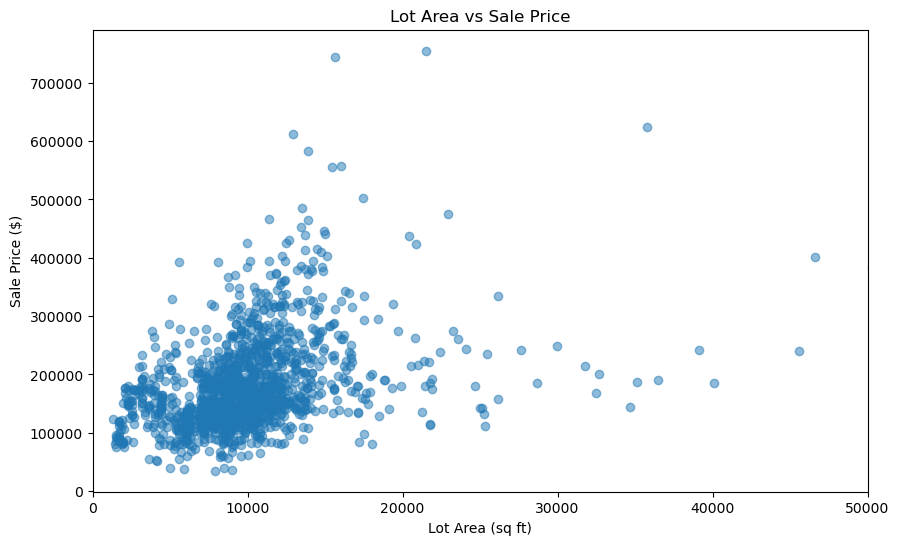

In [15]:
# Scatterplot: LotArea & SalePrice
# Question: Do houses with larger lots tend to have higher sale prices?

plt.figure(figsize=(10,6))
plt.scatter(train_data["LotArea"], train_data["SalePrice"], alpha=0.5)

plt.xlabel("Lot Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.title("Lot Area vs Sale Price")

plt.xlim(0,50000)
plt.show()

In [16]:
# Correlation
train_data["LotArea"].corr(train_data["SalePrice"])

np.float64(0.2638433538714056)

In [17]:
""" CONCLUSION
LotArea has a weak positive linear relationship with SalePrice. Lot size may contain useful information, but it is unlikely to explain house prices by itself.
"""

' CONCLUSION\nLotArea has a weak positive linear relationship with SalePrice. Lot size may contain useful information, but it is unlikely to explain house prices by itself.\n'

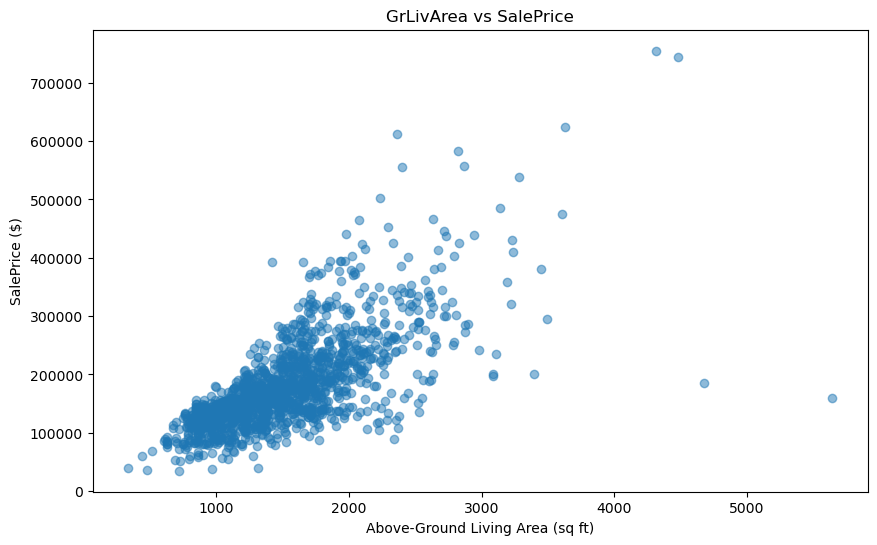

In [18]:
# Scatterplot: Above-Ground Living Area & SalePrice
# Question: Do houses with larger above-ground living areas tend to have higher sale prices?

plt.figure(figsize=(10,6))
plt.scatter(train_data["GrLivArea"], train_data["SalePrice"], alpha=0.5)

plt.xlabel("Above-Ground Living Area (sq ft)")
plt.ylabel("SalePrice ($)")
plt.title("GrLivArea vs SalePrice")    

plt.show()

In [19]:
train_data["GrLivArea"].corr(train_data["SalePrice"])

np.float64(0.7086244776126523)

In [20]:
""" CONCLUSION
The scatter plot reveals a clear positive relationship between above-ground living area (GrLivArea) and house sale price (SalePrice).
The Pearson correlation coefficient is approximately 0.709, indicating a relatively strong positive linear association.
GrLivArea is a promising feature for predicting house prices. Both GrLivArea and LotArea should be considered as candidate predictors, with their actual contribution evaluated through model validation.
"""

' CONCLUSION\nThe scatter plot reveals a clear positive relationship between above-ground living area (GrLivArea) and house sale price (SalePrice).\nThe Pearson correlation coefficient is approximately 0.709, indicating a relatively strong positive linear association.\nGrLivArea is a promising feature for predicting house prices. Both GrLivArea and LotArea should be considered as candidate predictors, with their actual contribution evaluated through model validation.\n'

<Axes: xlabel='OverallQual', ylabel='SalePrice'>

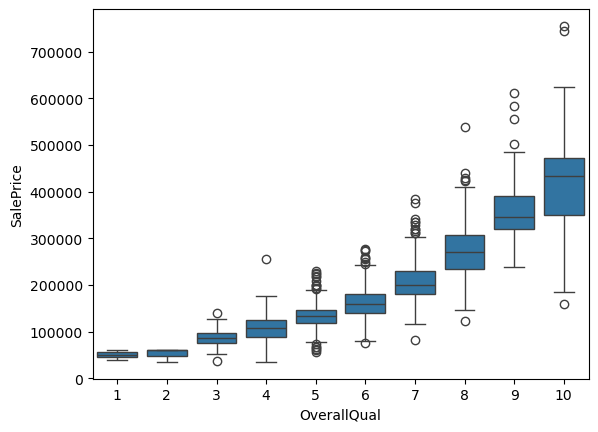

In [21]:
# BoxPlot : OverallQual & SalePrice
# Question: How do sale prices change across the overall quality scores?
sns.boxplot(data=train_data, x="OverallQual", y="SalePrice")

In [22]:
""" CONCLUSION
Sale prices generally increase with overall house quality. Higher-quality properties also show greater price variability and some outliers.
OverallQual is a promising feature for predicting SalePrice.
"""

' CONCLUSION\nSale prices generally increase with overall house quality. Higher-quality properties also show greater price variability and some outliers.\nOverallQual is a promising feature for predicting SalePrice.\n'

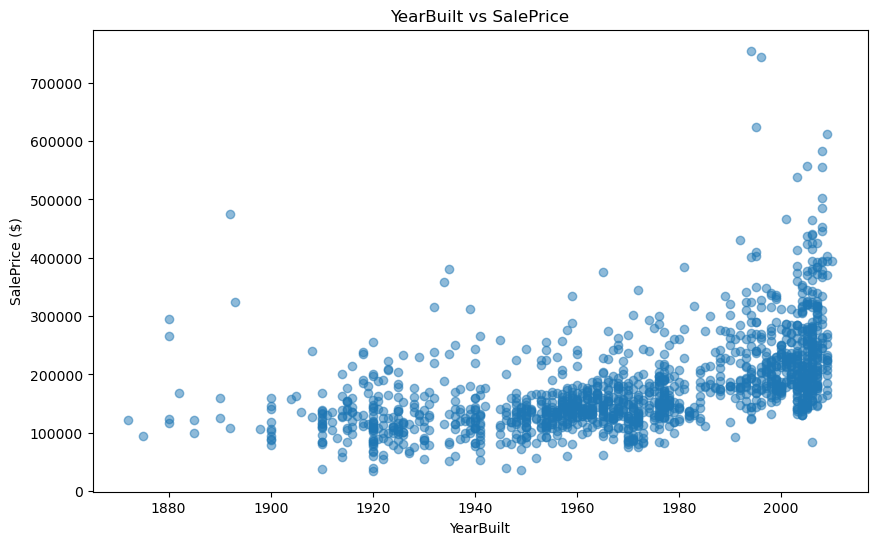

In [23]:
# Scatterplot: YearBuilt & SalePrice
# Question: Do newer houses tend to sell for higher prices?
plt.figure(figsize=(10,6))
plt.scatter(train_data["YearBuilt"], train_data["SalePrice"], alpha=0.5)

plt.xlabel("YearBuilt")
plt.ylabel("SalePrice ($)")
plt.title("YearBuilt vs SalePrice")

plt.show()

In [24]:
train_data["YearBuilt"].corr(train_data["SalePrice"])

np.float64(0.5228973328794969)

In [25]:
""" CONCLUSION
A moderate positive correlation (r = 0.523) suggests that newer houses generally tend to have higher sale prices, particularly those built after 2000.
YearBuilt is a promising feature for predicting SalePrice, although other factors also influence property values.
"""

' CONCLUSION\nA moderate positive correlation (r = 0.523) suggests that newer houses generally tend to have higher sale prices, particularly those built after 2000.\nYearBuilt is a promising feature for predicting SalePrice, although other factors also influence property values.\n'

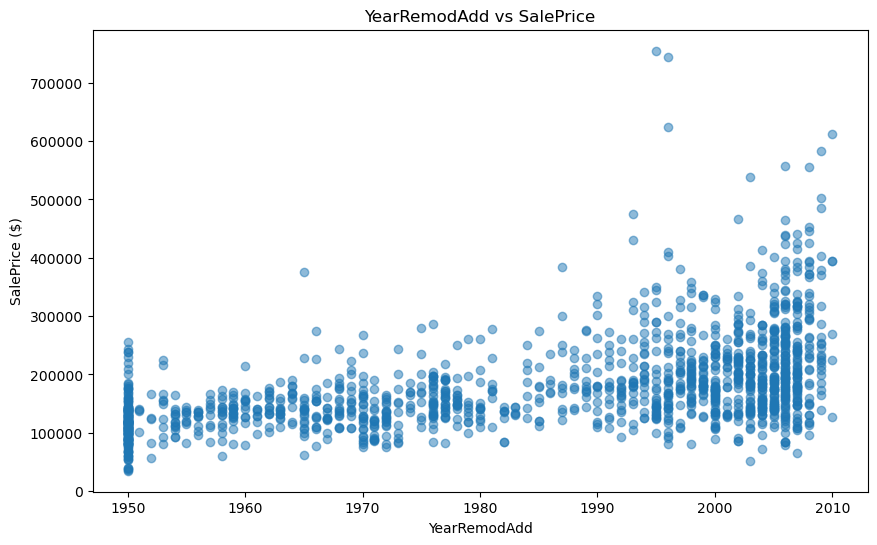

In [26]:
# Scatterplot: YearRemodAdd & SalePrice
# Question: Do houses remodeled more recently tend to sell for higher prices?
plt.figure(figsize=(10,6))
plt.scatter(train_data["YearRemodAdd"], train_data["SalePrice"], alpha=0.5)

plt.xlabel("YearRemodAdd")
plt.ylabel("SalePrice ($)")
plt.title("YearRemodAdd vs SalePrice")

plt.show()

In [27]:
train_data["YearRemodAdd"].corr(train_data["SalePrice"])

np.float64(0.5071009671113865)

In [28]:
""" CONCLUSION
YearRemodAdd shows a moderate positive correlation with SalePrice (r = 0.507), suggesting that more recently built or remodeled houses tend to have higher prices.
Both YearBuilt and YearRemodAdd are potential predictors worth evaluating together.
"""

' CONCLUSION\nYearRemodAdd shows a moderate positive correlation with SalePrice (r = 0.507), suggesting that more recently built or remodeled houses tend to have higher prices.\nBoth YearBuilt and YearRemodAdd are potential predictors worth evaluating together.\n'

In [29]:
# Exploratory feature engineering
eda_data = train_data.copy()

# Calculate the number of years between construction and remodeling
eda_data["DiffYear"] = eda_data["YearRemodAdd"] - eda_data["YearBuilt"]
eda_data["DiffYear"].corr(eda_data["SalePrice"])

np.float64(-0.21750331522000182)

In [30]:
""" CONCLUSION
`DiffYear`, calculated as `YearRemodAdd - YearBuilt`, shows a weak negative correlation with `SalePrice` (r = -0.218).
Its predictive value remains uncertain and should be evaluated during model validation.
"""

' CONCLUSION\n`DiffYear`, calculated as `YearRemodAdd - YearBuilt`, shows a weak negative correlation with `SalePrice` (r = -0.218).\nIts predictive value remains uncertain and should be evaluated during model validation.\n'

In [31]:
# Year Since Remodel
# Calculate the number of years between remodeling and sale
eda_data["YearSinceRemodel"]= eda_data["YrSold"] - eda_data["YearRemodAdd"]
eda_data["YearSinceRemodel"].corr(eda_data["SalePrice"])

np.float64(-0.5090787380156292)

In [32]:
""" CONCLUSION
YearsSinceRemodel shows a moderate negative correlation with SalePrice (r = -0.509), suggesting that more recently built or remodeled properties tend to have higher prices.
This engineered feature is a promising candidate for model validation.
"""

' CONCLUSION\nYearsSinceRemodel shows a moderate negative correlation with SalePrice (r = -0.509), suggesting that more recently built or remodeled properties tend to have higher prices.\nThis engineered feature is a promising candidate for model validation.\n'

In [33]:
# Missing LotFrontage values
# Descriptive statistics for the known LotFrontage values
train_data["LotFrontage"].describe()

count    1201.000000
mean       70.049958
std        24.284752
min        21.000000
25%        59.000000
50%        69.000000
75%        80.000000
max       313.000000
Name: LotFrontage, dtype: float64

In [34]:
# Count rows where LotFrontage is missing
missing_lot_frontage = train_data["LotFrontage"].isna().sum()

In [35]:
# Calculate the percentage of rows where LotFrontage is missing
missing_lot_frontage_percent = train_data["LotFrontage"].isna().mean() * 100

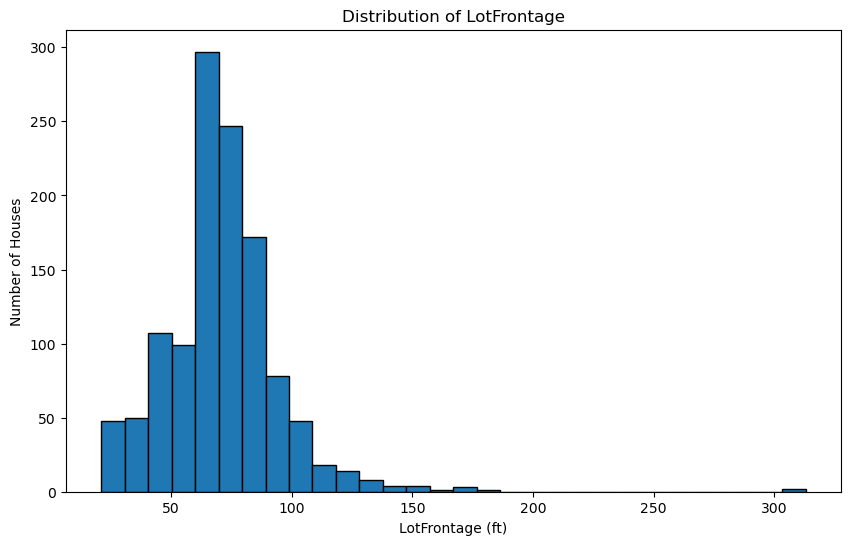

In [36]:
# Histogram
plt.figure(figsize=(10,6))
plt.hist(train_data["LotFrontage"].dropna(), bins=30, edgecolor="black")

plt.xlabel("LotFrontage (ft)")
plt.ylabel("Number of Houses")
plt.title("Distribution of LotFrontage")

plt.show()

In [37]:
# Calculate the average of the known LotFrontage values
train_data["LotFrontage"].mean()

np.float64(70.04995836802665)

In [38]:
# Calculate the median of the known LotFrontage values
train_data["LotFrontage"].median()

69.0

In [39]:
""" CONCLUSION
The `LotFrontage` distribution is right-skewed, with most values concentrated around 60–70 ft and some high-value outliers.
Median imputation is a reasonable starting approach because it is less sensitive to outliers. Neighborhood-based median imputation may provide more accurate estimates.
"""

' CONCLUSION\nThe `LotFrontage` distribution is right-skewed, with most values concentrated around 60–70 ft and some high-value outliers.\nMedian imputation is a reasonable starting approach because it is less sensitive to outliers. Neighborhood-based median imputation may provide more accurate estimates.\n'

In [40]:
# Calculate the median LotFrontage for each neighborhood
train_data.groupby("Neighborhood")["LotFrontage"].median()

Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.0
CollgCr    70.0
Crawfor    74.0
Edwards    65.5
Gilbert    65.0
IDOTRR     60.0
MeadowV    21.0
Mitchel    73.0
NAmes      73.0
NPkVill    24.0
NWAmes     80.0
NoRidge    91.0
NridgHt    88.5
OldTown    60.0
SWISU      60.0
Sawyer     71.0
SawyerW    66.5
Somerst    73.5
StoneBr    61.5
Timber     85.0
Veenker    68.0
Name: LotFrontage, dtype: float64

In [41]:
""" CONCLUSION
Median LotFrontage varies significantly across neighborhoods, ranging from 21 to 91 ft.
Neighborhood-based median imputation may be more appropriate than using a single global median.
"""

' CONCLUSION\nMedian LotFrontage varies significantly across neighborhoods, ranging from 21 to 91 ft.\nNeighborhood-based median imputation may be more appropriate than using a single global median.\n'

In [42]:
# Count known LotFrontage values in each neighborhood
train_data.groupby("Neighborhood")["LotFrontage"].count()

Neighborhood
Blmngtn     14
Blueste      2
BrDale      16
BrkSide     51
ClearCr     13
CollgCr    126
Crawfor     41
Edwards     92
Gilbert     49
IDOTRR      34
MeadowV     15
Mitchel     36
NAmes      186
NPkVill      7
NWAmes      45
NoRidge     33
NridgHt     76
OldTown    109
SWISU       23
Sawyer      48
SawyerW     50
Somerst     78
StoneBr     20
Timber      30
Veenker      7
Name: LotFrontage, dtype: int64

In [43]:
# Count all houses in each neighborhood, including missing LotFrontage values
train_data.groupby("Neighborhood")["LotFrontage"].size()

Neighborhood
Blmngtn     17
Blueste      2
BrDale      16
BrkSide     58
ClearCr     28
CollgCr    150
Crawfor     51
Edwards    100
Gilbert     79
IDOTRR      37
MeadowV     17
Mitchel     49
NAmes      225
NPkVill      9
NWAmes      73
NoRidge     41
NridgHt     77
OldTown    113
SWISU       25
Sawyer      74
SawyerW     59
Somerst     86
StoneBr     25
Timber      38
Veenker     11
Name: LotFrontage, dtype: int64

In [44]:
# Count missing LotFrontage values by neighborhood
missing_by_neighborhood = train_data.groupby("Neighborhood")["LotFrontage"].size() - train_data.groupby("Neighborhood")["LotFrontage"].count() 

In [45]:
# Calculate the percentage of missing LotFrontage values
missing_percentage = missing_by_neighborhood/ train_data.groupby("Neighborhood")["LotFrontage"].size()*100
missing_percentage.sort_values(ascending=False)

Neighborhood
ClearCr    53.571429
NWAmes     38.356164
Gilbert    37.974684
Veenker    36.363636
Sawyer     35.135135
Mitchel    26.530612
NPkVill    22.222222
Timber     21.052632
StoneBr    20.000000
Crawfor    19.607843
NoRidge    19.512195
Blmngtn    17.647059
NAmes      17.333333
CollgCr    16.000000
SawyerW    15.254237
BrkSide    12.068966
MeadowV    11.764706
Somerst     9.302326
IDOTRR      8.108108
Edwards     8.000000
SWISU       8.000000
OldTown     3.539823
NridgHt     1.298701
BrDale      0.000000
Blueste     0.000000
Name: LotFrontage, dtype: float64

In [46]:
""" CONCLUSION
ClearCr has the highest missing-value percentage (53.57%), with only 13 known LotFrontage values.
Neighborhood-based median imputation is worth testing, but neighborhoods with limited observations may require a global-median fallback.
"""

' CONCLUSION\nClearCr has the highest missing-value percentage (53.57%), with only 13 known LotFrontage values.\nNeighborhood-based median imputation is worth testing, but neighborhoods with limited observations may require a global-median fallback.\n'

In [47]:
# MISSING VALUES VERIFICATE

In [48]:
train_data["YearsSinceRemodel"]= train_data["YrSold"] - train_data["YearRemodAdd"]

In [49]:
# Select input features
features = ["OverallQual", "GrLivArea", "YearBuilt", "YearsSinceRemodel"]
X = train_data[features]

# Select target variable
y= train_data["SalePrice"]


In [50]:
X.isnull().sum()

OverallQual          0
GrLivArea            0
YearBuilt            0
YearsSinceRemodel    0
dtype: int64

In [51]:
# TRAIN/VALIDATE SPLIT

In [52]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split( X, y, test_size = 0.2, random_state= 42 )

In [53]:
X_train.shape

(1168, 4)

In [54]:
X_valid.shape

(292, 4)

In [55]:
y_train.shape

(1168,)

In [56]:
 y_valid.shape

(292,)

In [57]:
# IMPORTS

# MODEL 1
from sklearn.linear_model import LinearRegression
# MODEL 2
from sklearn.tree import DecisionTreeRegressor
# MODEL 3
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error


In [58]:
# FIRST BASELINE MODEL - LINEAR REGRESSION

In [59]:
#Initialize Linear Regression model 
lr_model = LinearRegression()

#Train the model
lr_model.fit(X_train,y_train)

# Predict validation prices
lr_predictions = lr_model.predict(X_valid)

# Calculate validation preices 
lr_mae = mean_absolute_error(lr_predictions,y_valid)
lr_mae

28028.147648414688

In [60]:
for feature, coefficient in zip(X_train.columns, lr_model.coef_):
    print(f"{feature}: {coefficient:.2f}")

print(f"Intercept: {lr_model.intercept_:.2f}")

OverallQual: 23503.24
GrLivArea: 59.60
YearBuilt: 442.77
YearsSinceRemodel: -249.12
Intercept: -920450.83


In [61]:
""" CONCLUSION
The model assigns positive coefficients to overall quality, living area, and construction year, while years since remodeling has a negative coefficient.
Overall quality has a particularly large estimated effect: a one-point increase corresponds to approximately $23,503 in predicted sale price, holding other features constant.
These coefficients describe associations learned by the model, not necessarily causal relationships.
"""

' CONCLUSION\nThe model assigns positive coefficients to overall quality, living area, and construction year, while years since remodeling has a negative coefficient.\nOverall quality has a particularly large estimated effect: a one-point increase corresponds to approximately $23,503 in predicted sale price, holding other features constant.\nThese coefficients describe associations learned by the model, not necessarily causal relationships.\n'

In [62]:
# SECOND BASELINE MODEL - DECISION TREE REGRESSION

In [63]:
# Initialize the model
dt_model = DecisionTreeRegressor(random_state=42)
#Train the model
dt_model.fit(X_train,y_train)
#Predict house price
dt_predictions = dt_model.predict(X_valid)
# Calculate validation error
dt_mae = mean_absolute_error(dt_predictions,y_valid)
dt_mae

29779.102739726026

In [64]:
""" CONCLUSION
The Decision Tree Regressor achieved a validation MAE of $29,779.10.
This means the model's predictions differ from actual house prices by approximately $29,779 on average.
Next step: Compare training and validation errors to identify potential overfitting and improve model performance.
"""

" CONCLUSION\nThe Decision Tree Regressor achieved a validation MAE of $29,779.10.\nThis means the model's predictions differ from actual house prices by approximately $29,779 on average.\nNext step: Compare training and validation errors to identify potential overfitting and improve model performance.\n"

In [65]:
# Predict prices for training data
train_predictions = dt_model.predict(X_train)

#Calculate training error
train_mae = mean_absolute_error(y_train , train_predictions)
train_mae

50.49743150684932

In [66]:
""" CONCLUSION
The Decision Tree Regressor achieved a training MAE of $50.49, compared to a validation MAE of $29,779.10.
The large performance gap indicates severe overfitting. Limiting tree complexity may improve generalization.
"""

' CONCLUSION\nThe Decision Tree Regressor achieved a training MAE of $50.49, compared to a validation MAE of $29,779.10.\nThe large performance gap indicates severe overfitting. Limiting tree complexity may improve generalization.\n'

In [67]:
# IMPROVE MDOEL

In [68]:
# Initialize the model
dt_model2 = DecisionTreeRegressor(random_state=42, max_depth=5)
#Train the model
dt_model2.fit(X_train,y_train)
#Predict house price
dt_predictions2 = dt_model2.predict(X_valid)
# Calculate validation error
dt_mae2 = mean_absolute_error(dt_predictions2,y_valid)
dt_mae2

26225.010092971246

In [69]:
# Predict prices for training data
train_predictions2 = dt_model2.predict(X_train)

#Calculate training error
train_mae2 = mean_absolute_error(y_train , train_predictions2)
train_mae2

22827.266715422393

In [70]:
"""
Limiting the Decision Tree depth to 5 increased the training MAE from $50.49 to $22,827.27, while reducing the validation MAE from $29,779.10 to $26,225.01.
he original model was severely overfitting. Reducing tree complexity improved generalization, although further hyperparameter tuning is needed.
"""

'\nLimiting the Decision Tree depth to 5 increased the training MAE from $50.49 to $22,827.27, while reducing the validation MAE from $29,779.10 to $26,225.01.\nhe original model was severely overfitting. Reducing tree complexity improved generalization, although further hyperparameter tuning is needed.\n'

In [71]:
depth_values = [3,5,7,10]

for depth in depth_values:
    dt_model3= DecisionTreeRegressor(random_state=42, max_depth = depth)
    dt_model3.fit(X_train,y_train)
    dt_predictions3 = dt_model3.predict(X_valid)

    dt_mae3 = mean_absolute_error(dt_predictions3,y_valid)
    print(f'Depth {depth} -> MAE {dt_mae3}')

Depth 3 -> MAE 30554.33772573
Depth 5 -> MAE 26225.010092971246
Depth 7 -> MAE 25886.22024315191
Depth 10 -> MAE 27414.314180022226


In [72]:
''' CONCLUSION
We evaluated different tree depths (3, 5, 7, and 10) to improve model generalization.
The best validation performance was achieved with max_depth=7, resulting in an MAE of $25,886.22, approximately 13.1% lower than the original model.
This demonstrates the importance of controlling model complexity to balance underfitting and overfitting
'''

' CONCLUSION\nWe evaluated different tree depths (3, 5, 7, and 10) to improve model generalization.\nThe best validation performance was achieved with max_depth=7, resulting in an MAE of $25,886.22, approximately 13.1% lower than the original model.\nThis demonstrates the importance of controlling model complexity to balance underfitting and overfitting\n'

In [73]:
# THIRD BASELINE MODEL - RANDOM FOREST REGRESSOR

In [74]:
# Initialize Random Forest with 100 trees
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train model
rf_model.fit(X_train,y_train)

# Predict validation prices
rf_predictions = rf_model.predict(X_valid)

# Calculate validation preices 
rf_mae = mean_absolute_error(rf_predictions,y_valid)
rf_mae


22945.74955960535

In [75]:
""" CONCLUSION
Linear Regression achieved a validation MAE of $28,028.15, outperforming the default Decision Tree ($29,779.10) but performing worse than the tuned Decision Tree ($25,886.22) and Random Forest ($22,945.75).
Linear Regression provides a useful baseline, while Random Forest currently achieves the best predictive performance among the tested models.
"""

' CONCLUSION\nLinear Regression achieved a validation MAE of $28,028.15, outperforming the default Decision Tree ($29,779.10) but performing worse than the tuned Decision Tree ($25,886.22) and Random Forest ($22,945.75).\nLinear Regression provides a useful baseline, while Random Forest currently achieves the best predictive performance among the tested models.\n'

In [76]:
                                                                                      # ADVANCED PREPROCESSING & FEATURE ENGINEERING

In [77]:
# Count unique neighborhoods
print(train_data["Neighborhood"].nunique())
# Check missing values
print(train_data["Neighborhood"].isnull().sum())
# Display the most frequent neighborhoods
print(train_data["Neighborhood"].value_counts().head(10))

25
0
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
Name: count, dtype: int64


In [78]:
# IMPLEMENT ONE-HOT ENCODING
new_features = [ "OverallQual", "GrLivArea", "YearBuilt", "YearsSinceRemodel", "Neighborhood"]

In [79]:
# Create the new feature matrix
X_new = train_data[new_features]

# Display the first five rows
X_new.head()

,OverallQual,GrLivArea,YearBuilt,YearsSinceRemodel,Neighborhood
0,7,1710,2003,5,CollgCr
1,6,1262,1976,31,Veenker
2,7,1786,2001,6,CollgCr
3,7,1717,1915,36,Crawfor
4,8,2198,2000,8,NoRidge


In [80]:
X_encoded = pd.get_dummies(X_new, columns=["Neighborhood"], dtype=int)
print(X_encoded.shape)
print(X_encoded.filter(like="Neighborhood").head())

(1460, 29)
   Neighborhood_Blmngtn  Neighborhood_Blueste  Neighborhood_BrDale  \
0                     0                     0                    0   
1                     0                     0                    0   
2                     0                     0                    0   
3                     0                     0                    0   
4                     0                     0                    0   

   Neighborhood_BrkSide  Neighborhood_ClearCr  Neighborhood_CollgCr  \
0                     0                     0                     1   
1                     0                     0                     0   
2                     0                     0                     1   
3                     0                     0                     0   
4                     0                     0                     0   

   Neighborhood_Crawfor  Neighborhood_Edwards  Neighborhood_Gilbert  \
0                     0                     0                     0   

In [81]:
# RETRAIN MODEL 
X_new_train, X_new_valid, y_new_train, y_new_valid = train_test_split( X_new, y, test_size=0.2,  random_state=42)

In [82]:
# PREPROCESSING PIPELINE
# IMPORTS
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

preprocessor = ColumnTransformer(transformers=[("neighborhood", OneHotEncoder(handle_unknown="ignore"), ["Neighborhood"])], remainder="passthrough")

In [83]:
# Create a preprocessing and modeling pipeline
rf_pipeline = Pipeline(steps=[("preprocessor",preprocessor),("model",RandomForestRegressor(n_estimators=100,random_state=42))])

# Train the pipeline
rf_pipeline.fit(X_new_train,y_new_train)

#Predict validation prices
new_predictions = rf_pipeline.predict(X_new_valid)

#Calculate validation MAE
new_mae = mean_absolute_error(y_new_valid, new_predictions)

print("Random Forest with Neighborhood MAE:", new_mae)

Random Forest with Neighborhood MAE: 21253.92964041096


In [84]:
""" CONCLUSION
We added Neighborhood as a categorical feature and applied One-Hot Encoding using a preprocessing pipeline.
The Random Forest validation MAE decreased from $22,945.75 to $21,253.93, an improvement of approximately 7.37%.
This suggests that neighborhood information contributes useful predictive information and improves model performance on the validation set.
"""

' CONCLUSION\nWe added Neighborhood as a categorical feature and applied One-Hot Encoding using a preprocessing pipeline.\nThe Random Forest validation MAE decreased from $22,945.75 to $21,253.93, an improvement of approximately 7.37%.\nThis suggests that neighborhood information contributes useful predictive information and improves model performance on the validation set.\n'

In [85]:
# MISSING VALUE IMPUTATION

In [86]:
features_with_frontage = [ "OverallQual", "GrLivArea", "YearBuilt", "YearsSinceRemodel", "Neighborhood", "LotFrontage"]
X_frontage = train_data[features_with_frontage]

print(X_frontage.isnull().sum())

OverallQual            0
GrLivArea              0
YearBuilt              0
YearsSinceRemodel      0
Neighborhood           0
LotFrontage          259
dtype: int64


In [87]:
# SIMPLEIMPUTER
from sklearn.impute import SimpleImputer

numeric_transformer = SimpleImputer(strategy="median")
numeric_features =  [ "OverallQual", "GrLivArea", "YearBuilt", "YearsSinceRemodel", "LotFrontage"]
categorical_features = ["Neighborhood"]

In [88]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor_2 = ColumnTransformer(transformers=[("num",numeric_transformer,numeric_features), ("cat", OneHotEncoder(handle_unknown="ignore"),categorical_features)])

In [89]:
# TRAAIN/VALIDATION SPLIT
X_frontage_train, X_frontage_valid, y_frontage_train, y_frontage_valid = train_test_split(X_frontage,y,test_size=0.2, random_state=42)

# BUILD PIPELINE
rf_pipeline_2 = Pipeline(steps=[("preprocessor",preprocessor_2),("model", RandomForestRegressor(n_estimators=100,random_state=42))])

# Train the pipeline
rf_pipeline_2.fit(X_frontage_train,y_frontage_train)

# Predict validation prices
frontage_predictions = rf_pipeline_2.predict(X_frontage_valid)

# Calculate validation MAE
frontage_mae = mean_absolute_error(y_frontage_valid,frontage_predictions )
frontage_mae

21604.66167808219

In [90]:
""" CONCLUSION
We added LotFrontage and handled missing values using median imputation within a preprocessing pipeline.
The validation MAE increased from $21,253.93 to $21,604.66, indicating that this feature did not improve performance under the current configuration.
Further experiments with neighborhood-based imputation may help determine whether LotFrontage provides additional predictive value.
"""

' CONCLUSION\nWe added LotFrontage and handled missing values using median imputation within a preprocessing pipeline.\nThe validation MAE increased from $21,253.93 to $21,604.66, indicating that this feature did not improve performance under the current configuration.\nFurther experiments with neighborhood-based imputation may help determine whether LotFrontage provides additional predictive value.\n'

In [91]:
# FIRST SUBMISSION

new_features = [ "OverallQual", "GrLivArea", "YearBuilt", "YearsSinceRemodel", "Neighborhood"]

rf_pipeline.fit(X_new,y)

test_data["YearsSinceRemodel"] = ( test_data["YrSold"] - test_data["YearRemodAdd"])
X_test = test_data[new_features]
# Predict house prices for Kaggle test data
test_predictions = rf_pipeline.predict(X_test)

# Create submission file
submission = pd.DataFrame({
    "Id": test_data["Id"],
    "SalePrice": test_predictions
})

submission.to_csv("submission.csv", index=False)

submission.head()


,Id,SalePrice
0,1461,111560.240000
1,1462,145562.500000
2,1463,163337.286667
3,1464,179176.000000
4,1465,190890.000000


In [92]:
print((submission["SalePrice"] <= 0).sum())

0


In [93]:
# MODEL IMPROVEMENT  - VERSION 2 

# Select features for Version 2
features_v2 = [ "OverallQual", "GrLivArea", "YearBuilt",  "YearsSinceRemodel",  "Neighborhood", "TotalBsmtSF", "GarageCars", "FullBath"]

X_v2 = train_data[features_v2]

# Check missing values
print(X_v2.isnull().sum())

# Check dataset dimensions
print(X_v2.shape)


OverallQual          0
GrLivArea            0
YearBuilt            0
YearsSinceRemodel    0
Neighborhood         0
TotalBsmtSF          0
GarageCars           0
FullBath             0
dtype: int64
(1460, 8)


In [94]:
# RANDOM FOREST V2
numerical_features_v2 = [ "OverallQual", "GrLivArea", "YearBuilt",  "YearsSinceRemodel", "TotalBsmtSF", "GarageCars", "FullBath"]
categorical_features_v2 = ["Neighborhood"]

preprocessor_v2 = ColumnTransformer(transformers=[("num",SimpleImputer(strategy="median"),numerical_features_v2),("cat", OneHotEncoder(handle_unknown="ignore"),categorical_features_v2)])

X_train_v2, X_valid_v2 , y_train_v2, y_valid_v2 = train_test_split(X_v2, y, test_size=0.2, random_state=42) 

rf_v2 = Pipeline(steps=[("preprocessor",preprocessor_v2),("model",RandomForestRegressor(n_estimators=100,random_state=42))])

#Train
rf_v2.fit(X_train_v2,y_train_v2)

# Predict
predictions_v2=rf_v2.predict(X_valid_v2)

# Evaluate
mae_v2 = mean_absolute_error(y_valid_v2, predictions_v2)
mae_v2

18254.14622146119

In [95]:
""" CONCLUSION
We added three numerical features: TotalBsmtSF, GarageCars, and FullBath, while retaining neighborhood encoding and median imputation in the preprocessing pipeline.
The validation MAE decreased from $21,253.93 to $18,254.15, an improvement of approximately 14.11%.
This indicates that the additional property characteristics provide useful predictive information.
"""

' CONCLUSION\nWe added three numerical features: TotalBsmtSF, GarageCars, and FullBath, while retaining neighborhood encoding and median imputation in the preprocessing pipeline.\nThe validation MAE decreased from $21,253.93 to $18,254.15, an improvement of approximately 14.11%.\nThis indicates that the additional property characteristics provide useful predictive information.\n'

In [96]:
# SUBMISSION

X_test_v2 = test_data[features_v2]
# Retrain the model on all labeled houses
rf_v2.fit(X_train_v2,y_train_v2)

test_predictions_v2=rf_v2.predict(X_test_v2)

# Create submission
submission_v2 = pd.DataFrame({
    "Id": test_data["Id"],
    "SalePrice": test_predictions_v2
})

submission_v2.to_csv("submission_v2.csv", index=False)

In [97]:
from sklearn.model_selection import cross_val_score

# Evaluate Random Forest V2 using 5-fold cross-validation
scores = cross_val_score(rf_v2,X_v2,y,cv=5,scoring="neg_mean_absolute_error")

# Convert negative scores to positive MAE values
mae_scores = -scores

print("MAE for each fold:", mae_scores)
print("Average MAE:", mae_scores.mean())


MAE for each fold: [19652.55582551 19934.81809989 19907.23554656 17086.11592526
 20729.37902096]
Average MAE: 19462.02088363231


In [ ]:
""" CONCLUSION
The Random Forest V2 pipeline achieved an average cross-validation MAE of $19,462.02 across five folds, with individual scores ranging from $17,086.12 to $20,729.38.
Cross-validation provides a more robust performance estimate than a single train-validation split and highlights variability across different subsets of the data.
"""

In [98]:

from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None]
}

grid_search = GridSearchCV(
    estimator=rf_v2,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_search.fit(X_v2, y)

print("Best parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)


Best parameters: {'model__max_depth': None, 'model__n_estimators': 200}
Best CV MAE: 19400.780671491084


In [ ]:
""" CONCLUSION
GridSearchCV selected 200 estimators with no maximum depth limit as the best configuration among the tested combinations.
The average cross-validation MAE decreased from $19,462.02 to $19,400.78, representing a modest improvement of approximately 0.31%.
Feature engineering has produced larger performance gains than hyperparameter tuning so far.
"""

In [99]:
# VERSION 3

# Get the best model from GridSearchCV
best_model = grid_search.best_estimator_

# Prepare test features
X_test_v3 = test_data[features_v2]

# Predict test house prices
predictions_v3 = best_model.predict(X_test_v3)

# Create submission
submission_v3 = pd.DataFrame({
    "Id": test_data["Id"],
    "SalePrice": predictions_v3
})

# Save predictions
submission_v3.to_csv("submission_v3.csv", index=False)

print(submission_v3.shape)


(1459, 2)


In [ ]:
""" CONCLUSION
Although GridSearchCV slightly improved the average cross-validation MAE, the Kaggle public MAE increased from $17,985.30 (V2) to $18,344.32 (V3).
This demonstrates that small cross-validation improvements do not always translate into better performance on unseen data.
Random Forest V2 remains the best-performing submission on the public leaderboard.
"""